In [1]:
import pandas as pd

In [3]:
df = pd.read_csv(
    r"D:\Eco-Project\co-emissions-per-capita.csv"
)

In [4]:
display(df.head())

,Entity,Code,Year,CO₂ emissions per capita
0,Afghanistan,AFG,1949,0.001992
1,Afghanistan,AFG,1950,0.010837
2,Afghanistan,AFG,1951,0.011625
3,Afghanistan,AFG,1952,0.011468
4,Afghanistan,AFG,1953,0.013123


In [5]:
print(df.columns.tolist())

['Entity', 'Code', 'Year', 'CO₂ emissions per capita']


In [6]:
print("Number of rows and columns:",df.shape)

Number of rows and columns: (26509, 4)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26509 entries, 0 to 26508
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Entity                    26509 non-null  object 
 1   Code                      25363 non-null  object 
 2   Year                      26509 non-null  int64  
 3   CO₂ emissions per capita  26509 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 828.5+ KB


In [8]:
df.isnull().sum()

Entity                         0
Code                        1146
Year                           0
CO₂ emissions per capita       0
dtype: int64

In [10]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [17]:
print("Total unique entities:", df["Entity"].nunique())
print("\nFirst 20 entities:")
print(sorted(df["Entity"].dropna().unique())[:20]
)

Total unique entities: 231

First 20 entities:
['Afghanistan', 'Africa', 'Albania', 'Algeria', 'Andorra', 'Angola', 'Anguilla', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Aruba', 'Asia', 'Asia (excl. China and India)', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Barbados']


In [19]:
print("Earlist year:",df["Year"].min())
print("Latest year:",df["Year"].max())
print("Total unique years:",df["Year"].nunique())

Earlist year: 1750
Latest year: 2024
Total unique years: 230


In [22]:
india_data=df[df["Entity"] == "India"].copy() 
india_data=india_data.sort_values("Year") 
display(india_data.head())

,Entity,Code,Year,CO₂ emissions per capita
11629,India,IND,1858,0.001631
11630,India,IND,1859,0.002622
11631,India,IND,1860,0.002641
11632,India,IND,1861,0.002036
11633,India,IND,1862,0.002246


In [28]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(12,6))
plt.plot(
    india_data["Year"],
    india_data["CO2 emissions per capita"], 
    marker="o",
    markersize=3 
)

plt.title(
    "CO2 Emissions Per Capita in india Over Time",
    fontsize=14 
)

plt.xlabel("Year") 
plt.ylabel("CO2 Emisssions Per Capita") 
plt.grid(True,alpha=0.3) 
plt.tight_layout() 
plt.show()

KeyError: 'CO2 emissions per capita'

<Figure size 1200x600 with 0 Axes>

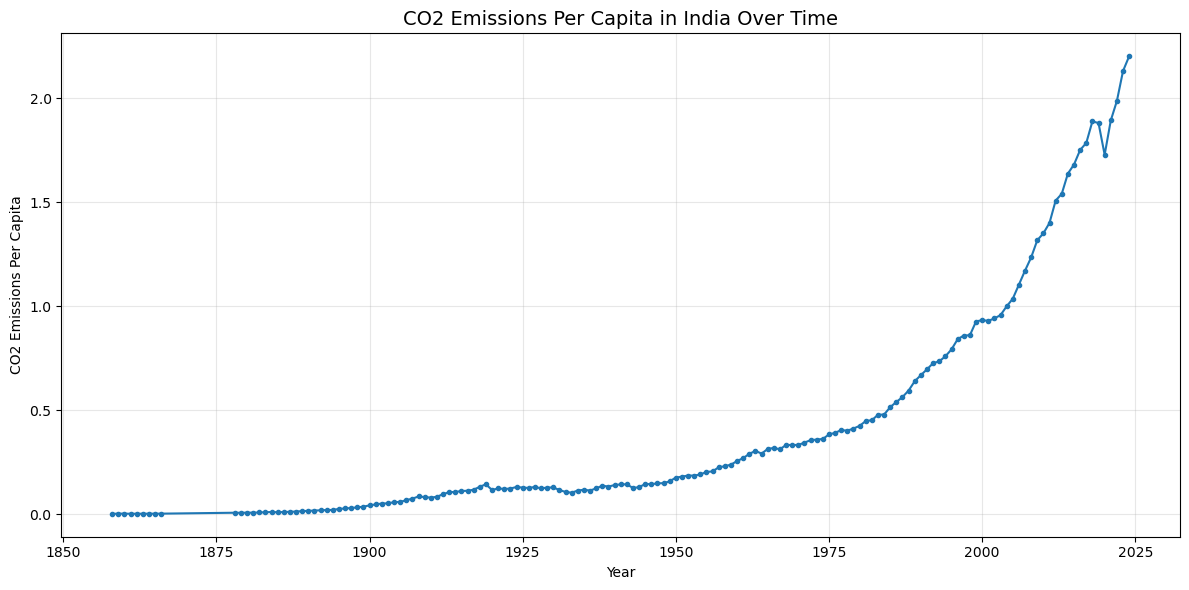

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    india_data["Year"],
    india_data["CO₂ emissions per capita"],
    marker="o",
    markersize=3
)

plt.title(
    "CO2 Emissions Per Capita in India Over Time",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("CO2 Emissions Per Capita")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
india_data["CO₂ emissions per capita"]

11629    0.001631
11630    0.002622
11631    0.002641
11632    0.002036
11633    0.002246
           ...   
11780    1.727293
11781    1.892074
11782    1.986169
11783    2.129769
11784    2.200978
Name: CO₂ emissions per capita, Length: 156, dtype: float64

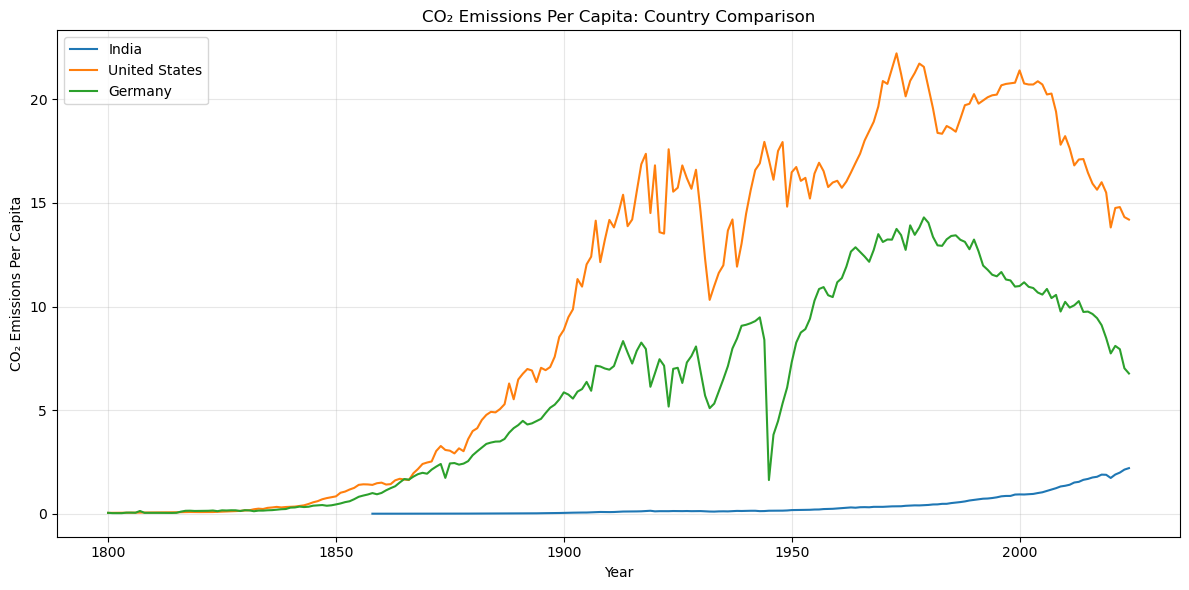

In [31]:
import matplotlib.pyplot as plt

# Select three countries
countries = ["India", "United States", "Germany"]

# Filter the original dataset
comparison = df[df["Entity"].isin(countries)].copy()

# Remove missing values for this chart
comparison = comparison.dropna(
    subset=["Year", "CO₂ emissions per capita"]
)

# Create the graph
plt.figure(figsize=(12, 6))

for country in countries:
    country_data = comparison[comparison["Entity"] == country]

    plt.plot(
        country_data["Year"],
        country_data["CO₂ emissions per capita"],
        label=country
    )

plt.title("CO₂ Emissions Per Capita: Country Comparison")
plt.xlabel("Year")
plt.ylabel("CO₂ Emissions Per Capita")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
print(comparison["Entity"].value_counts())

Entity
Germany          225
United States    225
India            156
Name: count, dtype: int64


In [33]:
for country in ["India", "United States", "Germany"]:
    country_data = comparison[comparison["Entity"] == country]

    print(
        country,
        "| First year:", country_data["Year"].min(),
        "| Last year:", country_data["Year"].max(),
        "| Records:", len(country_data)
    )

India | First year: 1858 | Last year: 2024 | Records: 156
United States | First year: 1800 | Last year: 2024 | Records: 225
Germany | First year: 1800 | Last year: 2024 | Records: 225


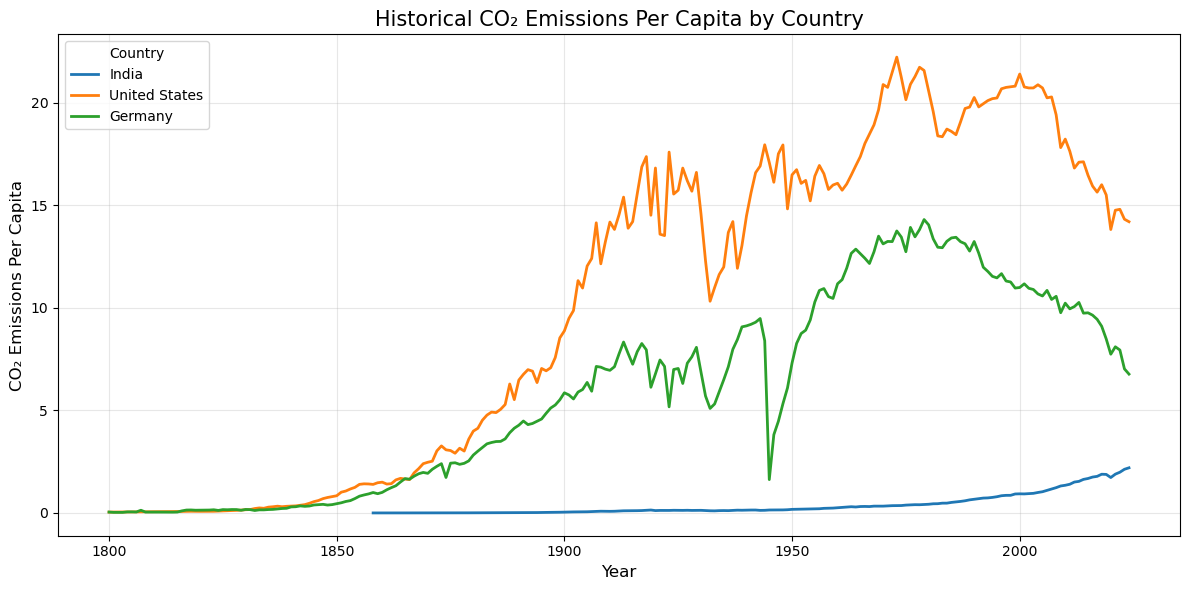

In [34]:
import matplotlib.pyplot as plt

# Countries we want to compare
countries = ["India", "United States", "Germany"]

# Create the graph
plt.figure(figsize=(12, 6))

for country in countries:

    # Select data for the current country
    country_data = comparison[
        comparison["Entity"] == country
    ].sort_values("Year")

    # Draw the line
    plt.plot(
        country_data["Year"],
        country_data["CO₂ emissions per capita"],
        label=country,
        linewidth=2
    )

# Add the title and labels
plt.title(
    "Historical CO₂ Emissions Per Capita by Country",
    fontsize=15
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("CO₂ Emissions Per Capita", fontsize=12)

# Improve readability
plt.legend(title="Country")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the graph
plt.show()

In [35]:
# Get the latest available record for each country
latest_data = (
    comparison
    .dropna(subset=["Year", "CO₂ emissions per capita"])
    .sort_values("Year")
    .groupby("Entity")
    .tail(1)
)

# Display the results
display(
    latest_data[
        ["Entity", "Year", "CO₂ emissions per capita"]
    ].sort_values("CO₂ emissions per capita", ascending=False)
)

,Entity,Year,CO₂ emissions per capita
25103,United States,2024,14.197287
9979,Germany,2024,6.768824
11784,India,2024,2.200978


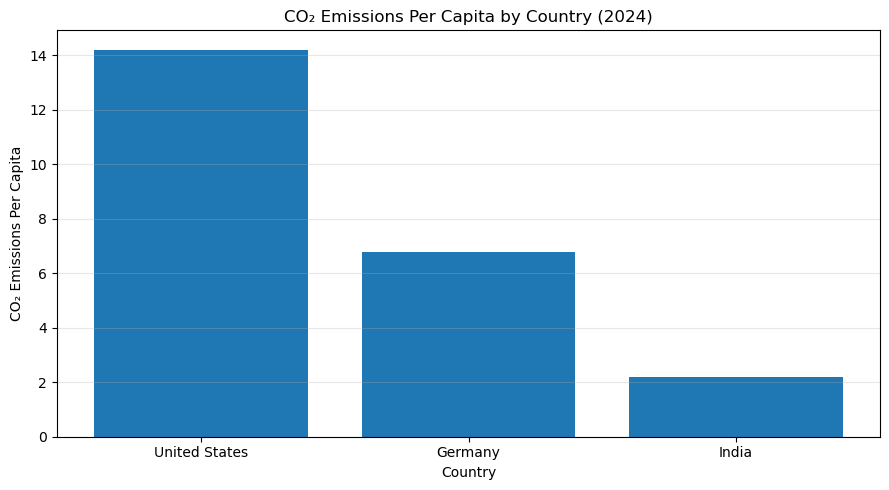

In [36]:
import matplotlib.pyplot as plt

# Sort countries from highest to lowest emissions
latest_sorted = latest_data.sort_values(
    "CO₂ emissions per capita",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    latest_sorted["Entity"],
    latest_sorted["CO₂ emissions per capita"]
)

plt.title("CO₂ Emissions Per Capita by Country (2024)")
plt.xlabel("Country")
plt.ylabel("CO₂ Emissions Per Capita")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# Get the latest emissions values
us_value = latest_data.loc[
    latest_data["Entity"] == "United States",
    "CO₂ emissions per capita"
].iloc[0]

germany_value = latest_data.loc[
    latest_data["Entity"] == "Germany",
    "CO₂ emissions per capita"
].iloc[0]

india_value = latest_data.loc[
    latest_data["Entity"] == "India",
    "CO₂ emissions per capita"
].iloc[0]

# Calculate percentage differences relative to India
us_difference = ((us_value - india_value) / india_value) * 100

germany_difference = (
    (germany_value - india_value) / india_value
) * 100

print(f"US emissions per capita are {us_difference:.2f}% higher than India's.")
print(f"Germany's emissions per capita are {germany_difference:.2f}% higher than India's.")

US emissions per capita are 545.04% higher than India's.
Germany's emissions per capita are 207.54% higher than India's.


In [38]:
print(df.columns.tolist())

['Entity', 'Code', 'Year', 'CO₂ emissions per capita']


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26509 entries, 0 to 26508
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Entity                    26509 non-null  object 
 1   Code                      25363 non-null  object 
 2   Year                      26509 non-null  int64  
 3   CO₂ emissions per capita  26509 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 828.5+ KB


In [40]:
import json

metadata_path = r"D:\Eco-Project\co-emissions-per-capita.metadata.json"

with open(metadata_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

print(json.dumps(metadata, indent=2)[:10000])

{
  "chart": {
    "title": "CO\u2082 emissions per capita",
    "citation": "Global Carbon Budget (2025); Population based on various sources (2024)",
    "originalChartUrl": "https://ourworldindata.org/grapher/co-emissions-per-capita?v=1&csvType=full&useColumnShortNames=false",
    "selection": [
      "World",
      "United States",
      "United Kingdom",
      "European Union (27)",
      "India",
      "China",
      "South Africa",
      "Canada",
      "Kenya"
    ]
  },
  "columns": {
    "Annual CO\u2082 emissions (per capita)": {
      "titleShort": "CO\u2082 emissions per capita",
      "titleLong": "CO\u2082 emissions per capita",
      "descriptionShort": "Carbon dioxide (CO\u2082) emissions from burning fossil fuels and industrial processes. This includes emissions from transport, electricity generation, and heating, but not land-use change.",
      "descriptionKey": "- Carbon dioxide (CO\u2082) is the primary greenhouse gas causing climate change.\n- Global CO\u2082 emi

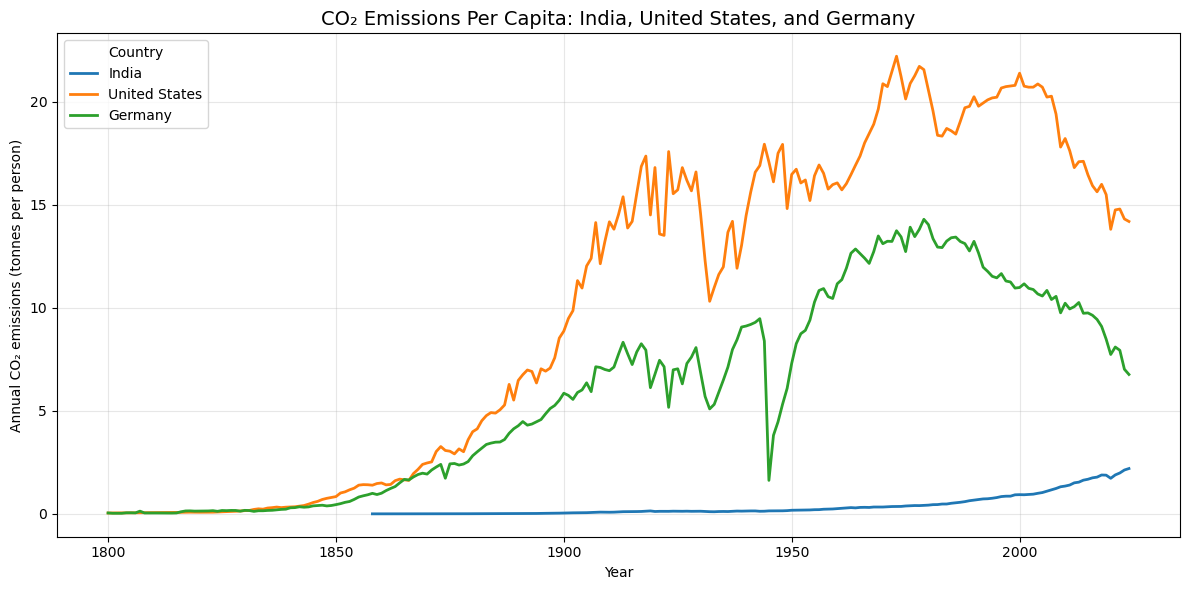

In [41]:
import matplotlib.pyplot as plt

# Countries to compare
countries = ["India", "United States", "Germany"]

# Create the figure
plt.figure(figsize=(12, 6))

# Draw one line for each country
for country in countries:

    country_data = comparison[
        comparison["Entity"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["CO₂ emissions per capita"],
        label=country,
        linewidth=2
    )

# Add informative labels
plt.title(
    "CO₂ Emissions Per Capita: India, United States, and Germany",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("Annual CO₂ emissions (tonnes per person)")

plt.legend(title="Country")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the graph
plt.show()

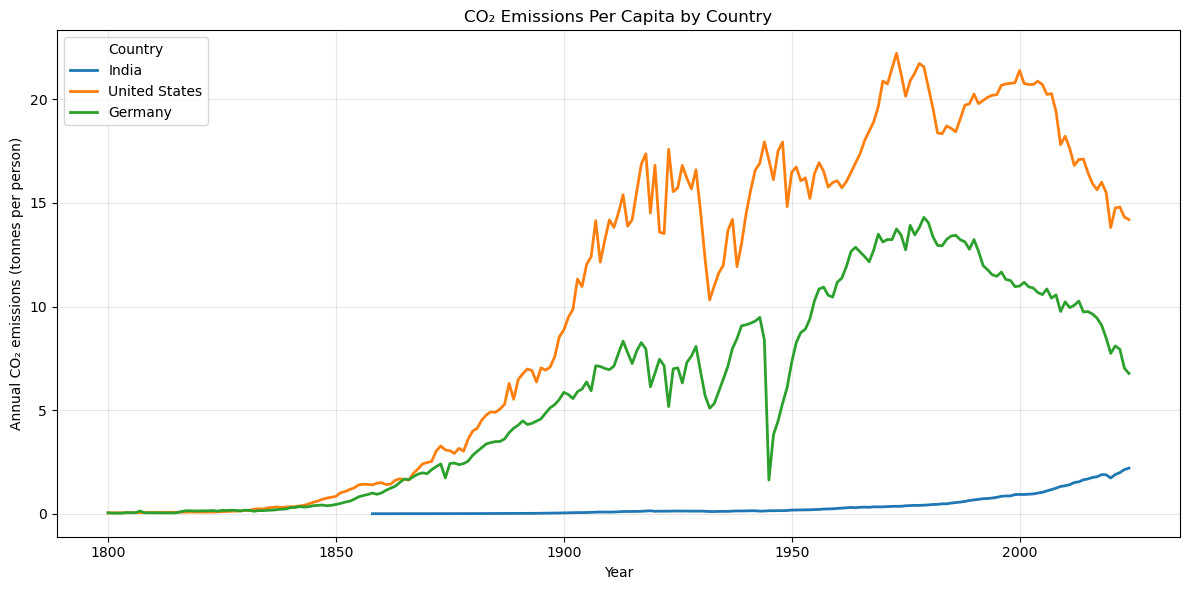

Graph saved successfully!


In [42]:
plt.figure(figsize=(12, 6))

for country in ["India", "United States", "Germany"]:

    country_data = comparison[
        comparison["Entity"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["CO₂ emissions per capita"],
        label=country,
        linewidth=2
    )

plt.title("CO₂ Emissions Per Capita by Country")
plt.xlabel("Year")
plt.ylabel("Annual CO₂ emissions (tonnes per person)")
plt.legend(title="Country")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph
plt.savefig(
    r"D:\Eco-Project\country_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

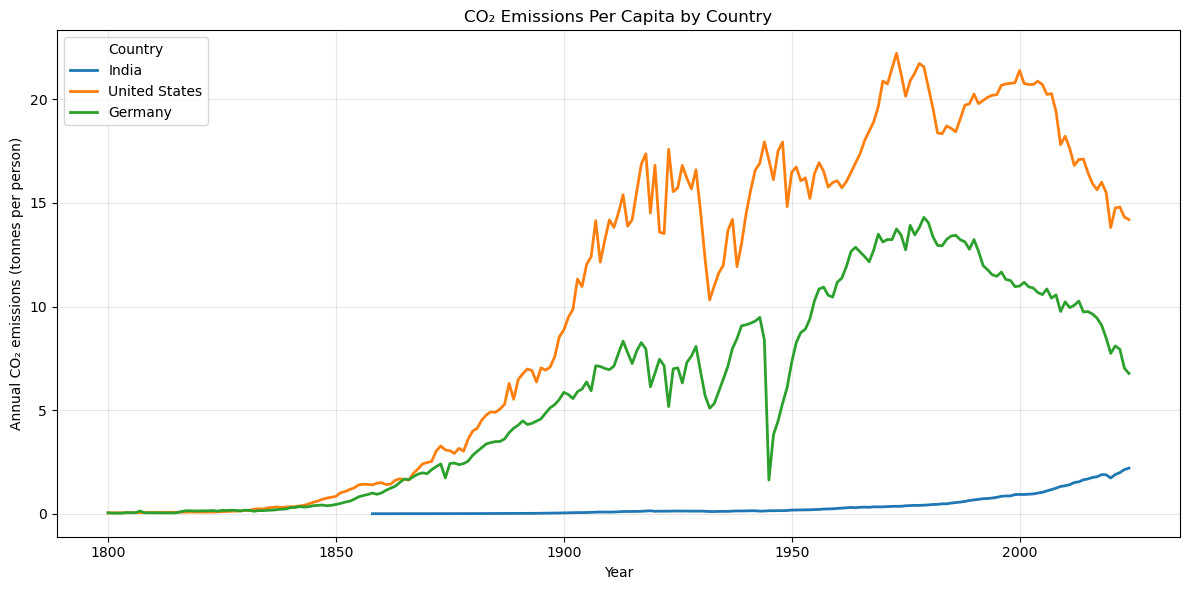

Graph saved successfully at: D:\Eco-Project\country_comparison.png


In [43]:
import matplotlib.pyplot as plt

# Create the graph
plt.figure(figsize=(12, 6))

for country in ["India", "United States", "Germany"]:

    country_data = comparison[
        comparison["Entity"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["CO₂ emissions per capita"],
        label=country,
        linewidth=2
    )

# Add graph title and labels
plt.title("CO₂ Emissions Per Capita by Country")
plt.xlabel("Year")
plt.ylabel("Annual CO₂ emissions (tonnes per person)")
plt.legend(title="Country")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph to your project folder
file_path = r"D:\Eco-Project\country_comparison.png"

plt.savefig(file_path, dpi=300, bbox_inches="tight")

# Display the graph
plt.show()

print("Graph saved successfully at:", file_path)

In [44]:
file_path = r"D:\Eco-Project\country_comparison.png"

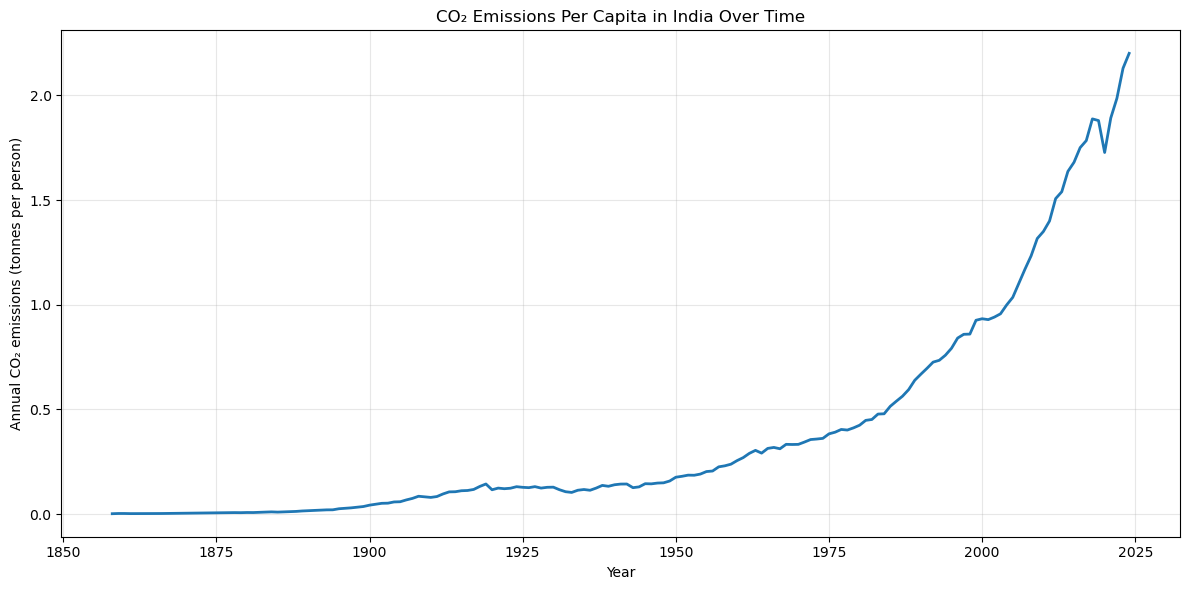

India graph saved successfully!


In [45]:
import matplotlib.pyplot as plt

# Sort India's data by year
india_data = india_data.sort_values("Year")

# Create the graph
plt.figure(figsize=(12, 6))

plt.plot(
    india_data["Year"],
    india_data["CO₂ emissions per capita"],
    linewidth=2
)

plt.title("CO₂ Emissions Per Capita in India Over Time")
plt.xlabel("Year")
plt.ylabel("Annual CO₂ emissions (tonnes per person)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph
plt.savefig(
    r"D:\Eco-Project\india_co2_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("India graph saved successfully!")

In [46]:
# Select the latest available record for each country
latest_data = (
    comparison
    .dropna(subset=["Year", "CO₂ emissions per capita"])
    .sort_values("Year")
    .groupby("Entity")
    .tail(1)
)

# Select the columns we need
results = latest_data[
    ["Entity", "Year", "CO₂ emissions per capita"]
].copy()

# Rename columns for a professional report
results = results.rename(columns={
    "Entity": "Country",
    "Year": "Year",
    "CO₂ emissions per capita": "CO2 emissions per person (tonnes)"
})

# Sort from highest to lowest
results = results.sort_values(
    "CO2 emissions per person (tonnes)",
    ascending=False
)

# Display the results
display(results)

,Country,Year,CO2 emissions per person (tonnes)
25103,United States,2024,14.197287
9979,Germany,2024,6.768824
11784,India,2024,2.200978


In [47]:
# Save the results table as a CSV file
file_path = r"D:\Eco-Project\co2_emissions_country_comparison.csv"

results.to_csv(file_path, index=False)

print("Results table saved successfully!")
print("File location:", file_path)

Results table saved successfully!
File location: D:\Eco-Project\co2_emissions_country_comparison.csv


In [48]:
# Calculate the average emissions per person for each country
average_emissions = (
    comparison
    .groupby("Entity")["CO₂ emissions per capita"]
    .mean()
    .reset_index()
)

# Rename the columns
average_emissions = average_emissions.rename(columns={
    "Entity": "Country",
    "CO₂ emissions per capita": "Average CO2 emissions per person (tonnes)"
})

# Sort from highest to lowest
average_emissions = average_emissions.sort_values(
    "Average CO2 emissions per person (tonnes)",
    ascending=False
)

# Display the results
display(average_emissions.round(2))

,Country,Average CO2 emissions per person (tonnes)
2,United States,10.16
0,Germany,5.88
1,India,0.41


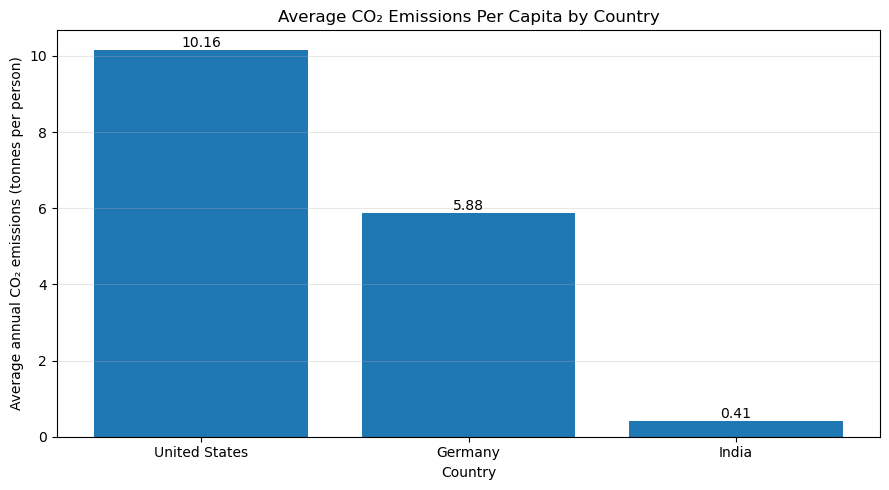

Average-emissions chart saved successfully!


In [49]:
import matplotlib.pyplot as plt

# Sort countries from highest to lowest average emissions
average_sorted = average_emissions.sort_values(
    "Average CO2 emissions per person (tonnes)",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    average_sorted["Country"],
    average_sorted["Average CO2 emissions per person (tonnes)"]
)

# Add a value label above each bar
plt.bar_label(bars, fmt="%.2f")

plt.title("Average CO₂ Emissions Per Capita by Country")
plt.xlabel("Country")
plt.ylabel("Average annual CO₂ emissions (tonnes per person)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig(
    r"D:\Eco-Project\average_emissions_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average-emissions chart saved successfully!")

In [50]:
average_emissions.to_csv(
    r"D:\Eco-Project\average_co2_emissions.csv",
    index=False
)

print("Average-emissions table saved successfully!")

Average-emissions table saved successfully!


In [51]:
from pathlib import Path

project_folder = Path(r"D:\Eco-Project")

print("Project folder exists:", project_folder.exists())
print("\nFiles in your project folder:")

for file in sorted(project_folder.iterdir()):
    print(file.name)

Project folder exists: True

Files in your project folder:
average_co2_emissions.csv
average_emissions_comparison.png
co-emissions-per-capita.csv
co-emissions-per-capita.metadata.json
co2_emissions_country_comparison.csv
country_comparison.png
india_co2_trend.png
readme.md


In [52]:
readme_content = """# CO2 Emissions Analysis: India, United States, and Germany

## Project Overview
This project analyzes historical CO2 emissions per capita for India,
the United States, and Germany using Python.

## Dataset
Source: Our World in Data
Original data source: Global Carbon Budget (2025)
Population data: Various sources (2024)
Unit: Tonnes per person

The dataset includes CO2 emissions from fossil fuels and industrial
processes but excludes land-use change.

Data source: https://ourworldindata.org/grapher/co-emissions-per-capita

## Tools
- Python
- pandas
- Matplotlib
- Jupyter Notebook

## Analysis
1. Loaded and inspected the dataset.
2. Filtered data for three countries.
3. Created historical emissions charts.
4. Compared latest available emissions values.
5. Calculated percentage differences relative to India.
6. Calculated average emissions across available observations.

## Key Findings: 2024
- United States: 14.20 tonnes per person.
- Germany: 6.77 tonnes per person.
- India: 2.20 tonnes per person.

US emissions per person were approximately 545% higher than India's.
Germany's emissions per person were approximately 208% higher than India's.

These are per-person comparisons, not total national emissions.

## Limitations
Historical coverage differs across countries, so their average values
are based on different sets of years. The data represents territorial
emissions rather than consumption-based emissions.

## Visualizations
- country_comparison.png
- india_co2_trend.png
- average_emissions_comparison.png

## Results
- co2_emissions_country_comparison.csv
- average_co2_emissions.csv

## Citation
Global Carbon Budget (2025); Population based on various sources (2024),
with major processing by Our World in Data.

https://ourworldindata.org/grapher/co-emissions-per-capita
"""

readme_path = project_folder / "PROJECT_README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("README saved successfully!")
print("Location:", readme_path)

README saved successfully!
Location: D:\Eco-Project\PROJECT_README.md


In [2]:
# Select data for India, the United States, and Germany
countries = ["India", "United States", "Germany"]

trend_data = df[
    (df["Entity"].isin(countries)) &
    (df["Year"].isin([2000, 2024]))
].copy()

# Display the data for 2000 and 2024
display(
    trend_data[
        ["Entity", "Year", "CO₂ emissions per capita"]
    ].sort_values(["Entity", "Year"])
)

NameError: name 'df' is not defined

In [3]:
import pandas as pd

# Load the original dataset
df = pd.read_csv(r"D:\Eco-Project\co-emissions-per-capita.csv")

# Display the first five rows
display(df.head())

,Entity,Code,Year,CO₂ emissions per capita
0,Afghanistan,AFG,1949,0.001992
1,Afghanistan,AFG,1950,0.010837
2,Afghanistan,AFG,1951,0.011625
3,Afghanistan,AFG,1952,0.011468
4,Afghanistan,AFG,1953,0.013123


In [4]:
# Select data for India, the United States, and Germany
countries = ["India", "United States", "Germany"]

trend_data = df[
    (df["Entity"].isin(countries)) &
    (df["Year"].isin([2000, 2024]))
].copy()

# Display the data for 2000 and 2024
display(
    trend_data[
        ["Entity", "Year", "CO₂ emissions per capita"]
    ].sort_values(["Entity", "Year"])
)

,Entity,Year,CO₂ emissions per capita
9955,Germany,2000,10.990293
9979,Germany,2024,6.768824
11760,India,2000,0.933022
11784,India,2024,2.200978
25079,United States,2000,21.397860
25103,United States,2024,14.197287


In [5]:
import pandas as pd

# Load the original dataset
df = pd.read_csv(r"D:\Eco-Project\co-emissions-per-capita.csv")

# Display the first five rows
display(df.head())

,Entity,Code,Year,CO₂ emissions per capita
0,Afghanistan,AFG,1949,0.001992
1,Afghanistan,AFG,1950,0.010837
2,Afghanistan,AFG,1951,0.011625
3,Afghanistan,AFG,1952,0.011468
4,Afghanistan,AFG,1953,0.013123


In [8]:

# Select data for India, the United States, and Germany
countries = ["India", "United States", "Germany"]

# Filter the dataset for the selected countries and years
trend_data = df[
    (df["Entity"].isin(countries)) &
    (df["Year"].isin([2000, 2024]))
].copy()

# Display the selected data
display(
    trend_data[
        ["Entity", "Year", "CO₂ emissions per capita"]
    ].sort_values(["Entity", "Year"])
)



,Entity,Year,CO₂ emissions per capita
9955,Germany,2000,10.990293
9979,Germany,2024,6.768824
11760,India,2000,0.933022
11784,India,2024,2.200978
25079,United States,2000,21.397860
25103,United States,2024,14.197287


In [10]:

# Reshape the data so each country has separate columns for 2000 and 2024
pivot_data = trend_data.pivot(
    index="Entity",
    columns="Year",
    values="CO₂ emissions per capita"
)

# Calculate the percentage change from 2000 to 2024
pivot_data["Percentage Change (%)"] = (
    (pivot_data[2024] - pivot_data[2000])
    / pivot_data[2000]
) * 100

# Rename columns for a clearer report
results = pivot_data.reset_index()

results = results.rename(columns={
    "Entity": "Country",
    2000: "Emissions in 2000",
    2024: "Emissions in 2024"
})


# Display the results
display(results.round(2))




Year,Country,Emissions in 2000,Emissions in 2024,Percentage Change (%)
0,Germany,10.99,6.77,-38.41
1,India,0.93,2.20,135.90
2,United States,21.40,14.20,-33.65


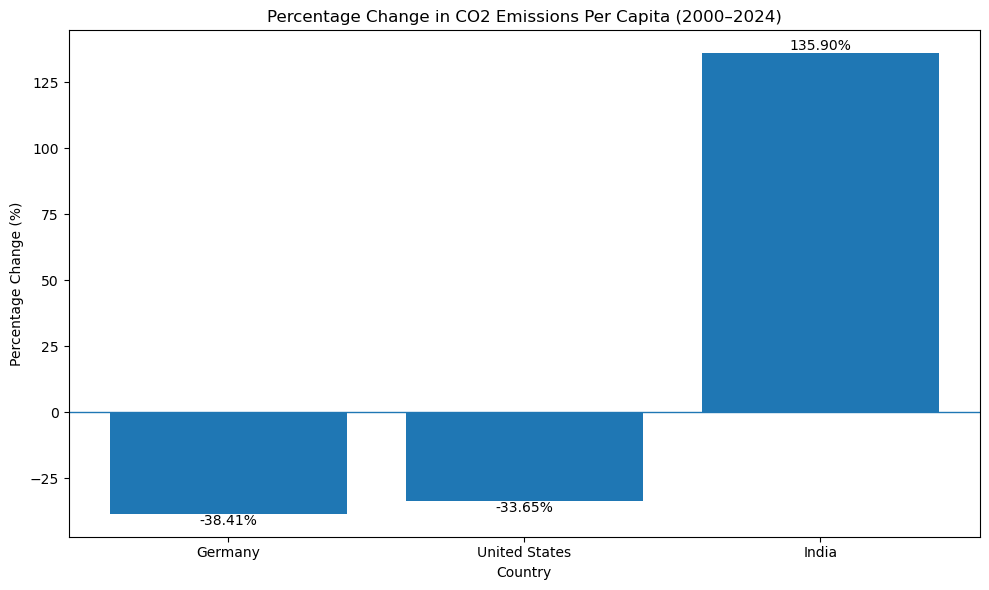

In [11]:
import matplotlib.pyplot as plt

# Sort countries by percentage change
chart_data = results.sort_values("Percentage Change (%)")

# Create the bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    chart_data["Country"],
    chart_data["Percentage Change (%)"]
)

# Add chart title and labels
plt.title("Percentage Change in CO2 Emissions Per Capita (2000–2024)")
plt.xlabel("Country")
plt.ylabel("Percentage Change (%)")

# Add a zero reference line
plt.axhline(y=0, linewidth=1)

# Display percentage values above or below bars
for index, value in enumerate(chart_data["Percentage Change (%)"]):
    plt.text(
        index,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()

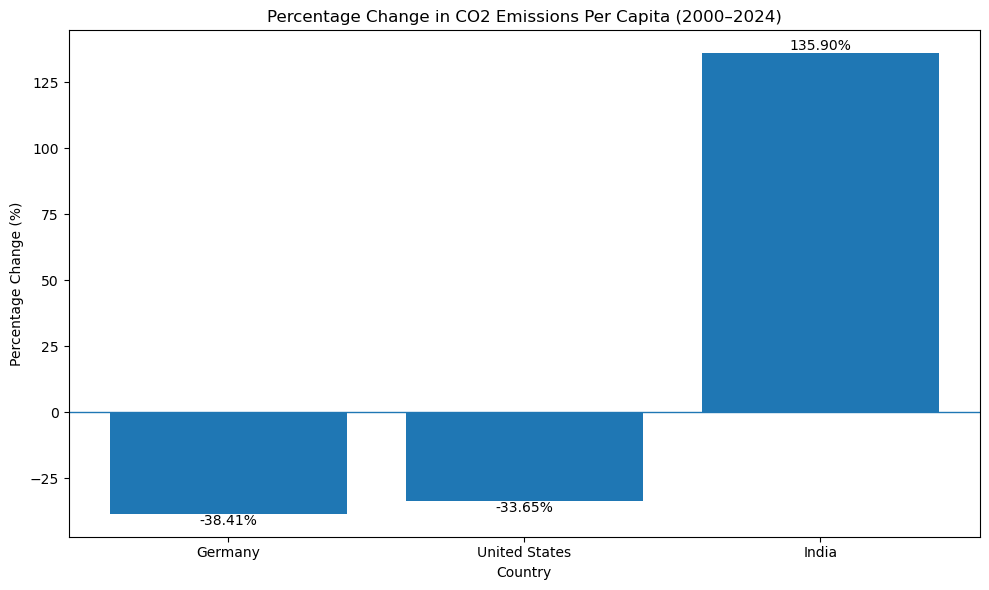

In [12]:
plt.figure(figsize=(10, 6))

plt.bar(
    chart_data["Country"],
    chart_data["Percentage Change (%)"]
)

plt.title("Percentage Change in CO2 Emissions Per Capita (2000–2024)")
plt.xlabel("Country")
plt.ylabel("Percentage Change (%)")

plt.axhline(y=0, linewidth=1)

for index, value in enumerate(chart_data["Percentage Change (%)"]):
    plt.text(
        index,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()

plt.savefig(
    r"D:\Eco-Project\percentage_change_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

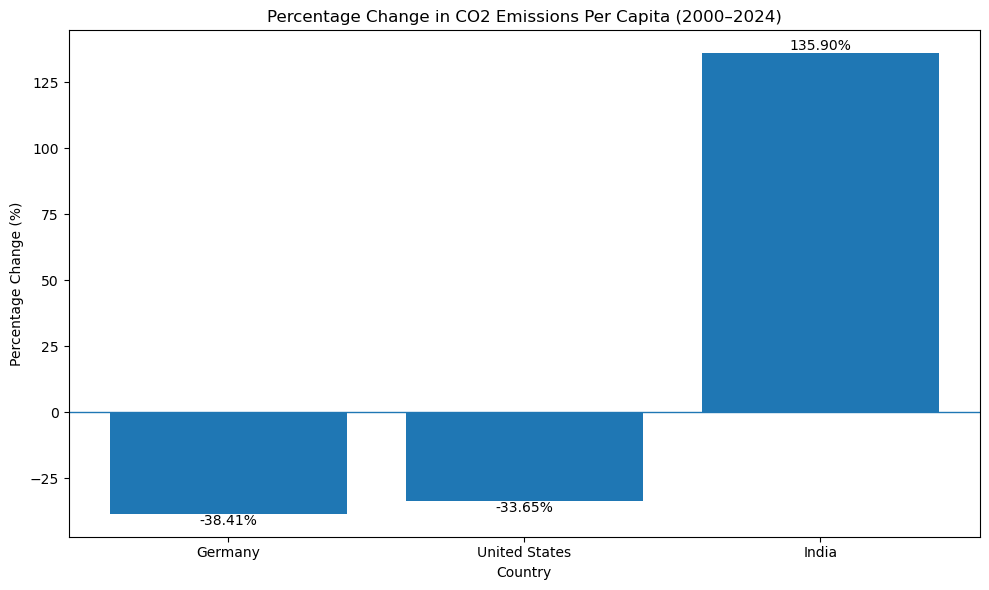

In [13]:
plt.figure(figsize=(10, 6))

plt.bar(
    chart_data["Country"],
    chart_data["Percentage Change (%)"]
)

plt.title("Percentage Change in CO2 Emissions Per Capita (2000–2024)")
plt.xlabel("Country")
plt.ylabel("Percentage Change (%)")

plt.axhline(y=0, linewidth=1)

for index, value in enumerate(chart_data["Percentage Change (%)"]):
    plt.text(
        index,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()

plt.savefig(
    r"D:\Eco-Project\percentage_change_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
from pathlib import Path

project_folder = Path(r"D:\Eco-Project")

for file in sorted(project_folder.iterdir()):
    if file.is_file():
        print(file.name)

average_co2_emissions.csv
average_emissions_comparison.png
co-emissions-per-capita.csv
co-emissions-per-capita.metadata.json
co2_emissions_country_comparison.csv
country_comparison.png
india_co2_trend.png
percentage_change_comparison.png
PROJECT_README.md
readme.md


In [20]:
from pathlib import Path

project_folder = Path(r"D:\Eco-Project")

notebook_path = project_folder / "co2_emissions_analysis.ipynb"

if notebook_path.exists():
    print("Notebook found successfully!")
else:
    print("Notebook is not yet saved in the project folder.")

Notebook is not yet saved in the project folder.


In [21]:
import os

# Display the current notebook working directory
print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\avkva


In [26]:
from pathlib import Path

# Search your current user folder for the notebook
search_folder = Path(r"C:\Users\avkva")

notebooks = list(search_folder.glob("**/co2_emissions_analysis.ipynb"))

if notebooks:
    for notebook in notebooks:
        print("Notebook found:", notebook)
else:
    print("Notebook not found in this folder.")

Notebook found: C:\Users\avkva\co2_emissions_analysis.ipynb
